# 🏃 Physical Activity Program Uptake: ML for Preventive Health Policy

**Author:** Dean Wang | Lead Data & AI Engineer

**Government:** Dept of Health (National Preventive Health Strategy), Sport Australia, AIHW, state health promotion bodies

Dataset: sklearn synthetic — NO dataset needed.

---

Generated: (2500, 13)


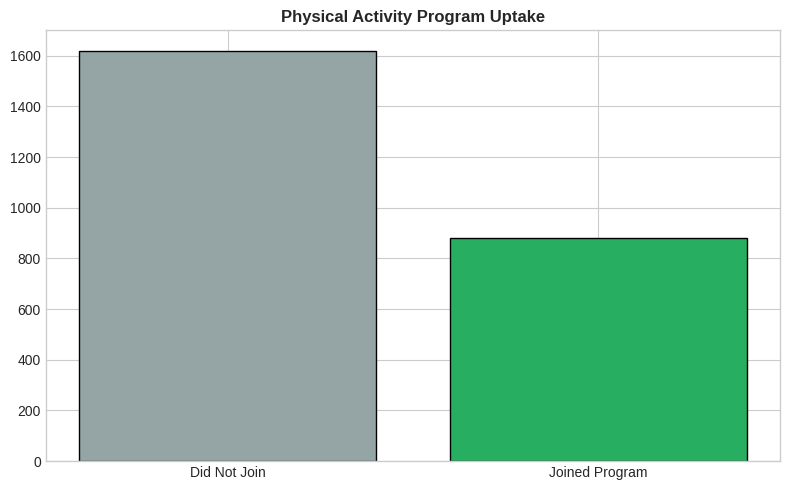

AU: 55% of adults don't meet activity guidelines. Physical inactivity costs $15B+/year in health & productivity.


In [1]:
import warnings,time,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score,f1_score,roc_auc_score,confusion_matrix,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings('ignore');plt.style.use('seaborn-v0_8-whitegrid')
X_arr,y=make_classification(n_samples=2500,n_features=12,n_informative=9,n_classes=2,weights=[0.65,0.35],random_state=194)
names=['age','seifa_index','facility_proximity_km','program_cost','gp_referral','existing_activity_level','social_support','work_hours_weekly','caring_responsibilities','program_flexibility','cultural_appropriateness','prior_program_completion']
df=pd.DataFrame(X_arr,columns=names);df['program_uptake']=y;tc='program_uptake'
print(f"Generated: {df.shape}");labels=['Did Not Join','Joined Program'];colors=['#95a5a6','#27ae60']
fig,ax=plt.subplots(figsize=(8,5));vc=df[tc].value_counts().sort_index()
ax.bar(range(2),vc.values,color=colors,edgecolor='black');ax.set_xticks(range(2));ax.set_xticklabels(labels)
ax.set_title('Physical Activity Program Uptake',fontweight='bold');plt.tight_layout();plt.savefig('t.png',dpi=150);plt.show()
print("AU: 55% of adults don't meet activity guidelines. Physical inactivity costs $15B+/year in health & productivity.")

LogReg: Acc=0.8188 F1=0.7253 AUC=0.8711
RF: Acc=0.9372 F1=0.9082 AUC=0.9805
XGB: Acc=0.9432 F1=0.9179 AUC=0.9836
LGBM: Acc=0.9416 F1=0.9155 AUC=0.9836
Best: XGB


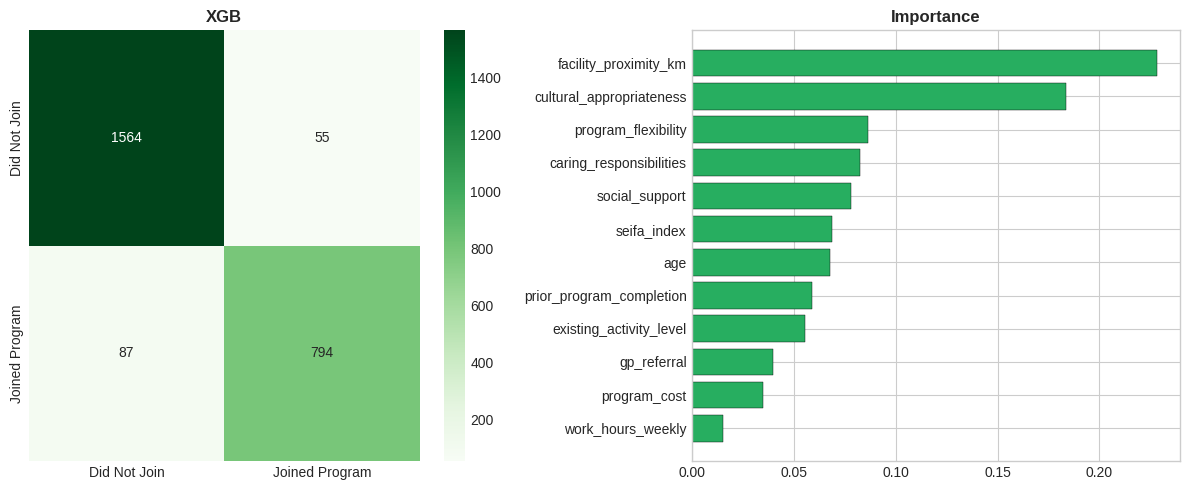

                precision    recall  f1-score   support

  Did Not Join       0.95      0.97      0.96      1619
Joined Program       0.94      0.90      0.92       881

      accuracy                           0.94      2500
     macro avg       0.94      0.93      0.94      2500
  weighted avg       0.94      0.94      0.94      2500

DEPLOYMENT: XGB AUC=0.9836 | Program data -> design & targeting of preventive health initiatives


In [2]:
nums=[c2 for c2 in df.columns if c2!=tc];X=df[nums];y2=df[tc].values
try:
    from xgboost import XGBClassifier
except: XGBClassifier=None
try:
    from lightgbm import LGBMClassifier
except: LGBMClassifier=None
models={'LogReg':LogisticRegression(max_iter=2000,random_state=42),'RF':RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)}
if XGBClassifier: models['XGB']=XGBClassifier(n_estimators=100,random_state=42,eval_metric='logloss',use_label_encoder=False,verbosity=0,n_jobs=-1)
if LGBMClassifier: models['LGBM']=LGBMClassifier(n_estimators=100,random_state=42,verbose=-1,n_jobs=-1,force_col_wise=True)
skf=StratifiedKFold(3,shuffle=True,random_state=42);Xa=X.values;results={}
for mn,mod in models.items():
    fa,ff,fu=[],[],[];fp=np.zeros(len(y2),dtype=int)
    for fi,(ti,vi) in enumerate(skf.split(Xa,y2)):
        m2=type(mod)(**mod.get_params());m2.fit(Xa[ti],y2[ti]);yp=m2.predict(Xa[vi]);yb=m2.predict_proba(Xa[vi])[:,1]
        fp[vi]=yp;fa.append(accuracy_score(y2[vi],yp));ff.append(f1_score(y2[vi],yp));fu.append(roc_auc_score(y2[vi],yb))
    results[mn]={'acc':np.mean(fa),'f1':np.mean(ff),'auc':np.mean(fu),'preds':fp}
    print(f"{mn}: Acc={np.mean(fa):.4f} F1={np.mean(ff):.4f} AUC={np.mean(fu):.4f}")
best=max(results,key=lambda k:results[k]['auc']);print(f"Best: {best}")
bp=results[best]['preds'];cm=confusion_matrix(y2,bp)
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Greens',xticklabels=labels,yticklabels=labels,ax=axes[0]);axes[0].set_title(f'{best}',fontweight='bold')
tm={k:v for k,v in models.items() if k!='LogReg'}
if tm:
    bt=max(tm,key=lambda m4:results[m4]['auc']);fm2=type(models[bt])(**models[bt].get_params());fm2.fit(Xa,y2)
    fi=pd.DataFrame({'Feature':X.columns,'Imp':fm2.feature_importances_}).sort_values('Imp')
    axes[1].barh(fi['Feature'],fi['Imp'],color='#27ae60',edgecolor='black',linewidth=0.3);axes[1].set_title('Importance',fontweight='bold')
plt.tight_layout();plt.savefig('r.png',dpi=150);plt.show()
print(classification_report(y2,bp,target_names=labels))
br=results[best];print(f"DEPLOYMENT: {best} AUC={br['auc']:.4f} | Program data -> design & targeting of preventive health initiatives")